> ### Note on Labs and Assignments:
>
> 🔧 Look for the **wrench emoji** 🔧 — it highlights where you're expected to take action!
>
> These sections are graded and are not optional.
>

# **IS 4487 LAB 11: Linear Regression for HR**

In this lab, we'll use an HR dataset to build a **linear regression model** to predict the number of years that an employee will work for the company (job tenure).


## Outline
1. Load and explore the dataset
2. Clean and prepare features
3. Encode categorical variables
4. Split the data into training and test sets
5. Train and evaluate a linear regression model
6. Reflect on variable importance and model fit
7. Understand regulaization with Lasso and Ridge regression models




<a href="https://colab.research.google.com/github/vandanara/UofUtah_IS4487/blob/main/Labs/lab_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## **Business Context: HR Turnover data**

A large company employs, at any given point of time, around 4000 employees. However, every year, around 15% of its employees leave the company and need to be replaced with the talent pool available in the job market. The management believes that this employee turnover is bad for the company, because of the following reasons -

- The former employees' projects get delayed, which makes it difficult to meet timelines, resulting in a reputation loss among consumers and partners
- A sizeable department has to be maintained, for the purposes of recruiting new talent
- More often than not, the new employees have to be trained for the job and/or given time to acclimatize themselves to the company

Hence, the management has contracted an HR analytics firm to understand what factors they should focus on, in order to increase the number of years that employees stay with the company. In other words, they want to know what changes they should make to their workplace, in order to get most of their employees to stay. Also, they want to know which of these variables is most important and needs to be addressed right away.

Since you are one of the star analysts at the firm, this project has been given to you.

### Goal of the case study
You are required to model the number of years employees work for the company using a linear regression model. The results thus obtained will be used by the management to understand what changes they should make to their workplace, in order to get most of their employees to stay.

**Target Variable:** `YearsAtCompany`

### Dataset Overview

**Dataset:** `merged_hr_data.csv`  
Source: [Kaggle HR Analytics Case Study](https://www.kaggle.com/datasets/vjchoudhary7/hr-analytics-case-study)

| Variable                      | Type        | Description |
|-------------------------------|-------------|-------------|
| `Age`                         | Numeric     | Age of the employee |
| `Attrition`                   | Categorical | Whether the employee has left the company (Yes/No) |
| `BusinessTravel`              | Categorical | Frequency of business travel |
| `Department`                  | Categorical | Department name |
| `DistanceFromHome`           | Numeric     | Distance from home to work (in km) |
| `Education`                  | Ordinal     | Employee education level (1–5) |
| `EducationField`             | Categorical | Field of education |
| `EmployeeCount`              | Constant    | Always 1 (not useful for modeling) |
| `EmployeeID`                 | Identifier  | Unique identifier for employee |
| `EnvironmentSatisfaction`    | Ordinal     | Satisfaction with the environment (1–4) |
| `Gender`                     | Categorical | Gender of the employee |
| `JobInvolvement`             | Ordinal     | Level of involvement with job (1–4) |
| `JobLevel`                   | Ordinal     | Employee level (1–5) |
| `JobRole`                    | Categorical | Job title |
| `JobSatisfaction`            | Ordinal     | Satisfaction with the job (1–4) |
| `MaritalStatus`              | Categorical | Marital status |
| `MonthlyIncome`              | Numeric     | Monthly salary in USD |
| `NumCompaniesWorked`         | Numeric     | Number of companies previously worked for |
| `Over18`                     | Constant    | Always "Y" (not useful) |
| `PercentSalaryHike`          | Numeric     | Percentage salary increase |
| `PerformanceRating`          | Ordinal     | Performance rating (1–4) |
| `StandardHours`              | Constant    | Always 8 (not useful) |
| `StockOptionLevel`           | Ordinal     | Stock options level (0–3) |
| `TotalWorkingYears`          | Numeric     | Total years of professional experience |
| `TrainingTimesLastYear`      | Numeric     | Number of training sessions attended last year |
| `WorkLifeBalance`            | Ordinal     | Work-life balance rating (1–4) |
| `YearsAtCompany`             | Numeric     | Years spent at the current company |
| `YearsSinceLastPromotion`    | Numeric     | Years since last promotion |
| `YearsWithCurrManager`       | Numeric     | Years with current manager |

**Target Variable:** `YearsAtCompany`

## **Part 1: Import packages, load and preview data**




In [33]:
import numpy as np
import pandas as pd

# Load the merged HR dataset
url = "https://raw.githubusercontent.com/vandanara/UofUtah_IS4487/refs/heads/main/DataSets/merged_hr_data.csv"
df = pd.read_csv(url)

# this is a wide dataset with many columns - increase display width to show all
pd.set_option('display.width', 1000)
pd.set_option('display.max_columns', None)


# Preview structure
print("Shape:", df.shape)
df.head()


Shape: (4410, 29)


,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeID,Gender,JobLevel,JobRole,MaritalStatus,MonthlyIncome,NumCompaniesWorked,Over18,PercentSalaryHike,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,JobInvolvement,PerformanceRating
0,51,No,Travel_Rarely,Sales,6,2,Life Sciences,1,1,Female,1,Healthcare Representative,Married,131160,1.0,Y,11,8,0,1.0,6,1,0,0,3.0,4.0,2.0,3,3
1,31,Yes,Travel_Frequently,Research & Development,10,1,Life Sciences,1,2,Female,1,Research Scientist,Single,41890,0.0,Y,23,8,1,6.0,3,5,1,4,3.0,2.0,4.0,2,4
2,32,No,Travel_Frequently,Research & Development,17,4,Other,1,3,Male,4,Sales Executive,Married,193280,1.0,Y,15,8,3,5.0,2,5,0,3,2.0,2.0,1.0,3,3
3,38,No,Non-Travel,Research & Development,2,5,Life Sciences,1,4,Male,3,Human Resources,Married,83210,3.0,Y,11,8,3,13.0,5,8,7,5,4.0,4.0,3.0,2,3
4,32,No,Travel_Rarely,Research & Development,10,1,Medical,1,5,Male,1,Sales Executive,Single,23420,4.0,Y,12,8,2,9.0,2,6,0,4,4.0,1.0,3.0,3,3


## **Part 2: Data Cleaning**

Real-world HR data often contains administrative fields (e.g., ID numbers), constants (same value for all rows), or missing values.

### What We’re Doing:
- Remove irrelevant or constant columns: `EmployeeCount`, `Over18`, `StandardHours`, `EmployeeID`
- Drop rows with missing data

### Why It Matters:
- Non-informative or redundant features can reduce model accuracy and interpretability.
- Regression does not handle missing values natively, so we need a clean dataset.
- Dropping some rows is reasonable here due to the relatively small number of nulls.

> Ethical Note: In practice, dropping rows may disproportionately exclude certain groups—so this step should be handled with caution.


In [34]:
# Drop unnecessary columns
drop_cols = ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeID', 'Attrition']
df.drop(columns=drop_cols, inplace=True)

# Drop rows with any missing values
df.dropna(inplace=True)

# Check result
print("After cleaning:", df.shape)


After cleaning: (4300, 24)


## **Part 3: Encode Categorical Variables**

### Ordinal/ ordered variables

Ordered variables should be integer encoded to make them numeric. For example, Education, JobInvolvement, JobLevel and others that are ordinal are already integer coded in this dataset, so we do not need to do anything more. These variables will be treated like numeric data.

### Nominal variables

Machine learning algorithms like linear regression require **numeric inputs**. To use nominal categorical data like `Gender` or `JobRole` (where order does not matter), we convert them into **dummy variables** using **one-hot encoding.**

Example:
Colors   |  col_Blue | col_Green  | col_Red    |
|--------|-------|--------|--------|
Blue     |   1   | 0      | 0      |
Green    |  0    | 1      | 0      |
Red      | 0     | 0      | 1      |

When a categorical variable is dummy coded, we should drop (any) one of the dummy variables in order to prevent **multicollinearity** which occurs when one of the column is a perfect linear combination of one or more other columns in the data. The Colors column is perfectly described by the sum of the three dummy columns.

This is perfect multicollinearity—the model cannot uniquely estimate the coefficients because the columns are perfectly redundant.

> SOLUTION: drop one dummy coded column.

### Key Steps:
- first **integer encode** all ordinal columns. Drop the original ordinal variable if present. In our data, this step has already been done. Else, you can use sklearn's `OrdinalEncoder` to fit and transform data
- second, perform **dummy variable encoding** using  `pd.get_dummies()` with `drop_first=True` to avoid multicollinearity. This function will convert *all* categorical columns (in our data all of which are nominal), into dummy variables.

### Why It Matters:
- Ensures model can interpret nominal categorical inputs numerically
- Dropping the first dummy prevents the **dummy variable trap** where one variable is a linear combination of others

> Reminder: Avoid encoding identifiers or columns with too many unique levels without reduction. Identifiers have no menainful relationship with outcomes. Too many dummy variables created due to having too many values in a caegorical variable will lead us to the other problem of **curse of dimensionality**, where patterns become harder to ascertain when data becomes sparse.



In [35]:
# One-hot encode all categorical features (here ones remaining are all nominal)
df_encoded = pd.get_dummies(df, drop_first=True)

# Preview encoded columns
display(df_encoded.head())
df_encoded.info()

,Age,DistanceFromHome,Education,JobLevel,MonthlyIncome,NumCompaniesWorked,PercentSalaryHike,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,JobInvolvement,PerformanceRating,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely,Department_Research & Development,Department_Sales,EducationField_Life Sciences,EducationField_Marketing,EducationField_Medical,EducationField_Other,EducationField_Technical Degree,Gender_Male,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single
0,51,6,2,1,131160,1.0,11,0,1.0,6,1,0,0,3.0,4.0,2.0,3,3,False,True,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
1,31,10,1,1,41890,0.0,23,1,6.0,3,5,1,4,3.0,2.0,4.0,2,4,True,False,True,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,True
2,32,17,4,4,193280,1.0,15,3,5.0,2,5,0,3,2.0,2.0,1.0,3,3,True,False,True,False,False,False,False,True,False,True,False,False,False,False,False,False,True,False,True,False
3,38,2,5,3,83210,3.0,11,3,13.0,5,8,7,5,4.0,4.0,3.0,2,3,False,False,True,False,True,False,False,False,False,True,True,False,False,False,False,False,False,False,True,False
4,32,10,1,1,23420,4.0,12,2,9.0,2,6,0,4,4.0,1.0,3.0,3,3,False,True,True,False,False,False,True,False,False,True,False,False,False,False,False,False,True,False,False,True


<class 'pandas.core.frame.DataFrame'>
Index: 4300 entries, 0 to 4408
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Age                                4300 non-null   int64  
 1   DistanceFromHome                   4300 non-null   int64  
 2   Education                          4300 non-null   int64  
 3   JobLevel                           4300 non-null   int64  
 4   MonthlyIncome                      4300 non-null   int64  
 5   NumCompaniesWorked                 4300 non-null   float64
 6   PercentSalaryHike                  4300 non-null   int64  
 7   StockOptionLevel                   4300 non-null   int64  
 8   TotalWorkingYears                  4300 non-null   float64
 9   TrainingTimesLastYear              4300 non-null   int64  
 10  YearsAtCompany                     4300 non-null   int64  
 11  YearsSinceLastPromotion            4300 non-null   int64  
 1

### **🔧 Try It Yourself - Part 3**

3.1. How many new columns were created during one-hot encoding?  you can compare the shape of the two dataframes in the outputs above.

3.2. Why is it important to avoid including columns like `EmployeeID` as a feature in predictive modeling?

3.3. Our model is trying to predict employment longevity.  Why is `Attrition` problematic for predicting years at the company?

Write a few sentences on each of the questions above. No coding is required here.

✍️ Your Response: 🔧

3.1.


3.2.


3.3.



## **Part 4: Train-Test Split**

Before splitting your data into training and test sets, you should only perform pre-processing steps that are strictly independent of other rows in the dataset.

So it is okay to do some cleaning (remove duplicates or missing values, fix data types and encoding categorical columns), as long as we do not rely on mean, median, min, max etc of the full data.

We should not perform any pre-processing that relies on knowing the distribution of the test set.

- standardization/normalization
- filling in mising values with mean/median,
- removing outliers

So before doing any further data transformation, we'll split the dataset into:
- 80% for training
- 20% for testing



In [36]:
from sklearn.model_selection import train_test_split

# Separate the features and the target
X = df_encoded.drop(columns=['YearsAtCompany'])
y = df_encoded['YearsAtCompany']

# Use already standardized features in X, and original target y
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Check the shapes of the splits
X_train.shape, X_test.shape



((3440, 37), (860, 37))

### **🔧 Try It Yourself - Part 4**

4.1. In the code cell below, calculate what average `YearsAtCompany` is for all employees


In [16]:
# 🔧 4.1 Add code here


### **Part 5: Standardizing Features for Regression**

When using models like **linear regression**, it's highly recommended to ensure all numeric features are on a similar scale. This helps the model converge more reliably and prevents features with larger magnitudes from dominating the learning process.

#### What data types to standardize?
- continuous: YES
- ordinal variables that are integer encoded: YES
- nominal categorical that are dummy coded/one-hot encoded: NO
- target variable: NO

In this step, we'll use `StandardScaler` from `sklearn` to scale all nuemric (continuous and integer-encoded feature) columns to have a mean of 0 and a standard deviation of 1. We do not scale the categorical features, as it would make their interpretation difficult.

This is especially important if your dataset includes variables with vastly different units or scales (e.g., "Age" vs. "MonthlyIncome")

> **Note:** The target variable (`YearsAtCompany`) should **not** be scaled — only the continuous input features.

---


In [37]:
from sklearn.preprocessing import StandardScaler

# PERFORM DATA TRANSFORMATIONS ON TRAINING DATA

# Identify numeric features from X_train to scale
X_train_num = X_train.select_dtypes(include=['int', 'float'])

# Apply standardization to the continuous features (leave out all categorical encoded features)
scaler = StandardScaler()
X_train_num_scaled = scaler.fit_transform(X_train_num)
type(X_train_num_scaled)

# Reconstruct scaled DataFrame from the output of StandardScaler and add column names to the DF
X_train_num_scaled = pd.DataFrame(X_train_num_scaled, columns=X_train_num.columns, index=X_train.index)

# combine this above DF with the DF of boolean columns selected from X_unscaled
X_train_boolean = X_train.select_dtypes(include=['bool'])
X_train = pd.concat([X_train_num_scaled, X_train_boolean], axis=1)

# Preview the final set of features
print(X_train.shape)
X_train.head()



(3440, 37)


,Age,DistanceFromHome,Education,JobLevel,MonthlyIncome,NumCompaniesWorked,PercentSalaryHike,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,YearsSinceLastPromotion,YearsWithCurrManager,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,JobInvolvement,PerformanceRating,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely,Department_Research & Development,Department_Sales,EducationField_Life Sciences,EducationField_Marketing,EducationField_Medical,EducationField_Other,EducationField_Technical Degree,Gender_Male,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single
2680,1.324262,-0.384212,-1.869840,0.832385,-0.747978,-0.269337,0.765024,0.244731,0.737589,-0.614605,-0.675440,1.084045,1.156259,-0.648571,-1.062452,-1.033687,-0.42867,True,False,True,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,True,False
3419,0.450606,-0.884237,0.076672,-0.066643,-0.377896,1.344106,0.219541,-0.927798,-0.413059,0.163548,-0.054595,-0.877615,1.156259,0.259851,0.343254,0.371245,-0.42867,False,True,True,False,True,False,False,False,False,True,False,False,False,False,False,True,False,False,False,True
3495,0.232192,-1.009243,0.076672,-0.066643,0.049236,1.747467,-0.325942,0.244731,1.248988,-0.614605,2.739211,0.243334,-1.585605,1.168273,0.343254,0.371245,-0.42867,True,False,False,True,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,False
1637,1.433469,0.115812,1.049928,0.832385,-0.368140,-1.076059,-0.871424,-0.927798,2.143936,0.163548,3.980902,0.803808,-0.671651,0.259851,0.343254,0.371245,-0.42867,False,True,False,True,True,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False
1662,-0.641464,-1.009243,1.049928,0.832385,-0.080770,0.537384,-0.598683,1.417260,-0.157359,-0.614605,-0.675440,0.243334,-0.671651,1.168273,1.748959,-1.033687,-0.42867,False,True,True,False,True,False,False,False,False,True,False,False,False,False,True,False,False,False,False,True


One can do any additional data transformations here, as well as feature engineering, as desired on the **training set**.

### **🔧 Try It Yourself - Part 5**

You've now scaled your features using `StandardScaler`, which makes each feature have a mean of 0 and a standard deviation of 1.

**Think about this:**
Suppose we didn't standardize the features and trained a regression model using raw input data instead. What might happen to the interpretation or relative importance of the coefficients?

5.1 Write one or two sentences explaining how not standardizing the data could affect the model's performance or interpretability.

### ✍️ Your Response: 🔧

5.1.


## **Part 6: Train the Regression Model**

Now we fit a linear regression model using the training data.  

In [55]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Initialize and train the Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Obtain coefficients
coefficients_linear = pd.Series(linear_model.coef_, index=X_train.columns)

# Display the features with the highest coefficients, ordered by magnitude
desc_sort_bymag_index = coefficients_linear.abs().sort_values(ascending=False).head(10).index
print("Top features by absolute coefficient magnitude (with actual values):")
display(coefficients_linear.loc[desc_sort_bymag_index])


Top features by absolute coefficient magnitude (with actual values):


,0
YearsWithCurrManager,2.829003
TotalWorkingYears,2.485182
YearsSinceLastPromotion,1.431609
EducationField_Medical,-0.929562
NumCompaniesWorked,-0.850759
EducationField_Technical Degree,-0.730991
EducationField_Life Sciences,-0.724575
JobRole_Manager,0.655916
Department_Research & Development,0.469019
EducationField_Marketing,-0.434769


### **🔧 Try It Yourself - Part 6**

Write a few sentences on each of the questions below. No coding is required here.

6.1. Which features are most positively associated with high job tenure (years at company)?

6.2. Which features are most negatively associated with staying?

### ✍️ Your Response: 🔧

6.1.

6.2.




## **Part 7: Evaluate Model Performance**

First, we have to ensure that we have to perform the exact same set of data transformations on test data set that were done to training data set in order to compare apples to apples.

Then, we can test how well our model generalizes to unseen data. We'll compute:
- Mean Squared Error (MSE)
- R-Squared



In [46]:
# PERFORM DATA TRANSFORMATIONS ON TEST DATA

# Identify numeric features from X_train to scale
X_test_num = X_test.select_dtypes(include=['int', 'float'])

# Apply standardization to the continuous features (leave out all categorical encoded features)
scaler = StandardScaler()
X_test_num_scaled = scaler.fit_transform(X_test_num)
type(X_test_num_scaled)

# Reconstruct scaled DataFrame from the output of StandardScaler and add column names to the DF
X_test_num_scaled = pd.DataFrame(X_test_num_scaled, columns=X_test_num.columns, index=X_test.index)

# combine this above DF with the DF of boolean columns selected from X_unscaled
X_test_boolean = X_test.select_dtypes(include=['bool'])
X_test = pd.concat([X_test_num_scaled, X_test_boolean], axis=1)

# Preview the final set of features
print(X_test.shape)
X_test.head()

(860, 37)


,Age,DistanceFromHome,Education,JobLevel,MonthlyIncome,NumCompaniesWorked,PercentSalaryHike,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,YearsSinceLastPromotion,YearsWithCurrManager,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,JobInvolvement,PerformanceRating,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely,Department_Research & Development,Department_Sales,EducationField_Life Sciences,EducationField_Marketing,EducationField_Medical,EducationField_Other,EducationField_Technical Degree,Gender_Male,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single
1815,0.864135,0.036041,1.104627,-0.959245,-0.178933,-0.695571,-0.897981,1.389023,-1.372176,-0.627992,-0.687911,-1.163960,-0.623671,0.209520,0.314026,0.423508,-0.418167,False,True,True,False,True,False,False,False,False,True,False,False,False,False,True,False,False,False,False,True
3122,-0.345143,0.864160,-1.857886,-0.959245,-0.952588,2.432225,1.845407,0.220178,-0.065631,1.663689,-0.687911,-0.601123,-0.623671,-1.601408,0.314026,1.840692,2.391391,True,False,False,True,False,True,False,False,False,True,False,False,False,False,True,False,False,False,False,False
1980,0.314463,-0.910381,0.117123,2.735942,-0.855130,-0.695571,-0.074965,0.220178,-0.457595,-0.627992,1.455579,0.243133,0.293178,-1.601408,-1.130157,0.423508,-0.418167,False,True,False,False,False,False,True,False,False,True,False,False,False,False,False,False,True,False,True,False
1226,-1.004749,-1.028683,1.104627,2.735942,0.785130,0.868327,-0.623642,-0.948667,-0.718904,-0.627992,-0.687911,-0.319705,0.293178,0.209520,0.314026,0.423508,-0.418167,False,True,True,False,True,False,False,False,False,True,False,False,False,False,True,False,False,False,False,True
114,-0.235208,2.283793,0.117123,0.888349,-0.308162,2.432225,-0.074965,-0.948667,-0.196286,-0.627992,-0.687911,-1.163960,0.293178,-0.695944,0.314026,0.423508,-0.418167,False,True,True,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True


In [47]:
# Make predictions on the test set
y_pred_train = linear_model.predict(X_train)
y_pred_test = linear_model.predict(X_test)

# Evaluate the model on both train and test data
train_mse = mean_squared_error(y_train, y_pred_train)
train_r2 = r2_score(y_train, y_pred_train)

test_mse = mean_squared_error(y_test, y_pred_test)
test_r2 = r2_score(y_test, y_pred_test)

# Print the evaluation metrics
print(f"Train R-squared (R2): {train_r2:.2f}")
print(f"Train Mean Squared Error (MSE): {train_mse:.2f}")

print(f"\nTest R-squared (R2): {test_r2:.2f}")
print(f"Test Mean Squared Error (MSE): {test_mse:.2f}")

Train R-squared (R2): 0.75
Train Mean Squared Error (MSE): 9.45

Test R-squared (R2): 0.76
Test Mean Squared Error (MSE): 9.23


Now visualize the model output - the regression line.

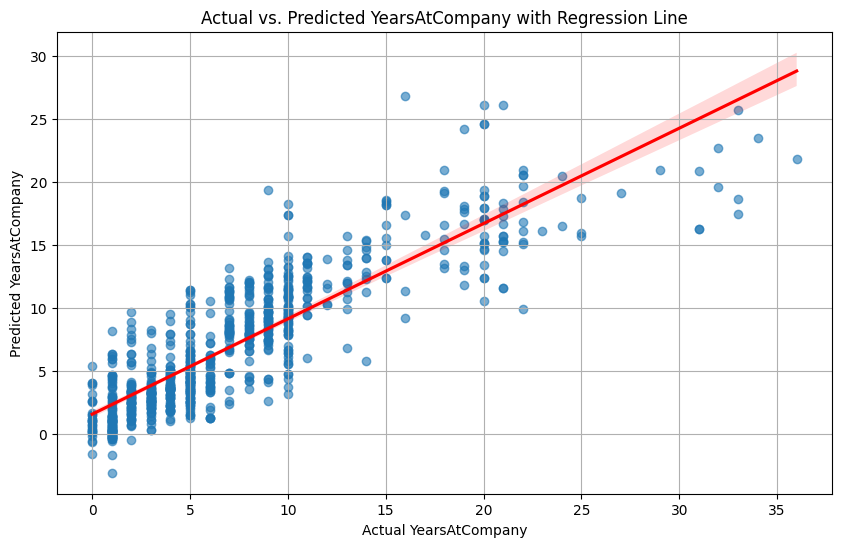

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a scatter plot of predicted vs actual YearsAtCompany
plt.figure(figsize=(10, 6))
ax = sns.regplot(x=y_test, y=y_pred_linear, scatter_kws={'alpha':0.6}, line_kws={"color": "red"})
ax.set_xlabel("Actual YearsAtCompany")
ax.set_ylabel("Predicted YearsAtCompany")
plt.title("Actual vs. Predicted YearsAtCompany with Regression Line")
plt.grid(True)
plt.show()

### **🔧 Try It Yourself - Part 7**

7.1. Is this R-squared for test data fit good? What can you say about overfitting or underfitting here? Which one is likely?

7.2. How could we improve the fit? what are some things you can try?

### ✍️ Your Response: 🔧

7.1.

7.2.

## **Part 8: Feature Engineering and Selection for Performance Improvement**

Since our model performance can be still improved, one thing to consider at this stage is **feature engineering**. Linear regression models can only learn straight-line relationships. If features interact or have curved relationships with the target (e.g., Age squared), standard linear regression misses them. We can automate the creation of these interactions and higher powers(rather than create them manually ourselves).

- We will use `sklearn.preprocessing.PolynomialFeatures`.

However doing so would generate a lot of columns (curse of dimensionality). We can then **automate the choosing of the best features/columns**.

- We can use `sklearn.feature_selection.SelectKBest`
- or use Regularization (L1 or L2 regression)

FEATURE ENGINEERING


In [66]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# 1. Select the numeric columns we want to create interactions for
numeric_cols = X_train.select_dtypes(include=['int', 'float']).columns

# 2. Initialize PolynomialFeatures (interaction_only=True prevents squaring terms if desired)
# degree=2 will create pairs of features (e.g., x1 * x2)
poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)

# 3. Fit and transform the numeric training and testing features
X_train_interactions = poly.fit_transform(X_train[numeric_cols])
X_test_interactions = poly.transform(X_test[numeric_cols])

# Get feature names for the new interaction features
poly_feature_names = poly.get_feature_names_out(numeric_cols)

# 4. Convert back to DataFrames
X_train_poly_df = pd.DataFrame(X_train_interactions, columns=poly_feature_names, index=X_train.index)
X_test_poly_df = pd.DataFrame(X_test_interactions, columns=poly_feature_names, index=X_test.index)

# 5. Combine with original boolean features
boolean_cols = X_train.select_dtypes(include=['bool']).columns
X_train_engineered = pd.concat([X_train_poly_df, X_train[boolean_cols]], axis=1)
X_test_engineered = pd.concat([X_test_poly_df, X_test[boolean_cols]], axis=1)

# 6. Train a new Linear Regression model
poly_model = LinearRegression()
poly_model.fit(X_train_engineered, y_train)

# 7. Make predictions and evaluate
y_pred_train_poly = poly_model.predict(X_train_engineered)
y_pred_test_poly = poly_model.predict(X_test_engineered)

print(f"New Train R-squared with Polynomials/ Interactions: {r2_score(y_train, y_pred_train_poly):.2f}")
print(f"New Test R-squared with Polynomials/ Interactions: {r2_score(y_test, y_pred_test_poly):.2f}")
print(f"Total features now: {X_train_engineered.shape[1]}")

New Train R-squared with Polynomials/ Interactions: 0.86
New Test R-squared with Polynomials/ Interactions: 0.86
Total features now: 173


FEATURE SELECTION

Let us manually find and select only the top 10 of the newly engineered polynomial and interaction features.

In [56]:
# Obtain coefficients
coefficients_poly = pd.Series(poly_model.coef_, index=X_train_engineered.columns)

# Show absolutely all rows (unlimited)
pd.set_option('display.max_rows', None)

# Display the features with the highest coefficients, ordered by magnitude
desc_sort_bymag_index = coefficients_poly.abs().sort_values(ascending=False).head(10).index
print("Top features by absolute coefficient magnitude (with actual values):")
display(coefficients_poly.loc[desc_sort_bymag_index])


Top features by absolute coefficient magnitude (with actual values):


,0
TotalWorkingYears,3.277176
YearsWithCurrManager,2.310029
TotalWorkingYears YearsSinceLastPromotion,1.178213
YearsSinceLastPromotion,1.163932
YearsSinceLastPromotion YearsWithCurrManager,-1.106881
EducationField_Medical,-0.907112
EducationField_Life Sciences,-0.876603
TotalWorkingYears YearsWithCurrManager,0.852293
NumCompaniesWorked TotalWorkingYears,-0.835638
Age TotalWorkingYears,-0.826991


### **🔧 Try It Yourself - Part 8**

8.1. Write code to retrain a linear regression model with only a smaller set of 10 most important features. Then evaluate this new model on the test set.

a. Create a new training and test set using only the 10 most important features.\
b. Retrain the linear regression model on this reduced dataset.\
c. Use the new model to predict on the test set.\
d. Evaluate performance of the new version using R2 and MSE.


In [ ]:
# 🔧 8.1 Add code here

Write a few sentences on each of the questions below. No coding is required here.

🔧 8.2. How did the reduced-feature model compare to the full model? Is it acceptable?

🔧 8.3. Would this version be easier to explain or use in an HR meeting?

### ✍️ Your Response: 🔧

8.2.

8.3.


## **Part 9: Regularization (Automated feature selection)**

We can use built-in techniques to reduce model complexity called **regularization** without having to arbitrarily choose the top x coefficients to keep.

- **Lasso (or L1) regression**:
    - Can shrink weak coefficients exactly to zero → performs feature selection.
    - Good when you expect only a few features to matter.
    - `LassoCV(alphas, cv`)
    
- **Ridge (or L2) regression**
    - Shrinks coefficients toward zero but never exactly to zero.
    - Useful when features are correlated; stabilizes the model.
    - `RidgeCV(alphas, cv)`
  

### How to select the hyperparameter alpha?
- *alpha* is the hyperparameter that allows us to define the regularization behavior.
- We can manually try different values, such as powers of 10, then powers of 2 etc. `alpha = 1` equals no regularization.
- OR we can use `LassoCV` or `RidgeCV`, two classes that perform crossvalidation. They will try several values in a specified range to automatically find the best alpha.

Below we will run `LassoCV()`.

Ridge is the exact same code, just change the name of the Class from `LassoCV` to `RidgeCV`.

In [65]:
from sklearn.linear_model import LassoCV

# Initialize and train the Lasso Regression model
lasso_model = LassoCV(alphas=np.logspace(-8, 8, 100), cv=5)    # specify several alphas to try
lasso_model.fit(X_train_engineered, y_train)

# Best alpha found
print("Best alpha:", lasso_model.alpha_)

# Make predictions on the test set
y_pred_lasso = lasso_model.predict(X_test_engineered)

# Evaluate the model
r2_lasso = r2_score(y_test, y_pred_lasso)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)

print(f"\nTest set Lasso Regression R-squared (R2): {r2_lasso:.2f}")
print(f"Test set Lasso Regression Mean Squared Error (MSE): {mse_lasso:.2f}")


# Display Lasso Coefficients to see which ones were kept
coefficients_lasso = pd.Series(lasso_model.coef_, index=X_train_engineered.columns)
print("\nLasso Regression Coefficients (ordered by absolute value, descending):")
print(coefficients_lasso.loc[coefficients_lasso.abs().sort_values(ascending=False).head(10).index])


Best alpha: 0.009545484566618348

Test set Lasso Regression R-squared (R2): 0.86
Test set Lasso Regression Mean Squared Error (MSE): 5.42

Lasso Regression Coefficients (ordered by absolute value, descending):
TotalWorkingYears                               3.178634
YearsWithCurrManager                            2.329237
YearsSinceLastPromotion                         1.164844
TotalWorkingYears YearsSinceLastPromotion       1.118389
YearsSinceLastPromotion YearsWithCurrManager   -1.085334
TotalWorkingYears YearsWithCurrManager          0.888972
NumCompaniesWorked TotalWorkingYears           -0.804074
NumCompaniesWorked                             -0.800026
Age TotalWorkingYears                          -0.760898
Age                                            -0.583395
dtype: float64


### **🔧 Try It Yourself - Part 9**

9.1. What do you observe about the performance of the regularized Lasso model on the test set compared to the full unregularized polynomial model (created by feature engineering in Part 8)?

9.2 Why does that happen?

### ✍️ Your Response: 🔧

9.1.

9.2.





## Export Your Notebook to Submit in Canvas
- Use the instructions from Lab 1

In [ ]:
!jupyter nbconvert --to html "lab_11_LastnameFirstname.ipynb"